# 02 · Clasificación: zero-shot, LLM y fine-tuning

Se clasifican los **titulares** de `datos/noticias.csv` en las 4 categorías oficiales
(`politica`, `economia`, `deportes`, `ciencia_tecnologia`). La etiqueta de referencia es la columna `etiqueta`,
derivada de la sección del diario donde se publicó cada noticia.

| Paso | Qué se hace | Resultado |
|---|---|---|
| 1 | Línea base zero-shot sobre 40 titulares | Piso mínimo a superar |
| 2 | Supervisión débil: Gemini etiqueta los 360 titulares + auditoría humana de 20 | `datos/etiquetas_llm.csv` |
| 3 | Split estratificado 70 / 15 / 15 (`random_state=42`) | Train / Val / Test |
| 4 | Fine-tuning de DistilBERT multilingüe **con las etiquetas del LLM** | Modelo en `modelo/` |
| 5 | Evaluación final en Test (aislado hasta este paso) | Accuracy, F1 macro, matriz de confusión |
| 6 | Comparativa y decisión | `modelo/comparativa.csv` |

Todos los modelos reciben **solo el titular**, para que la comparación sea justa.

## 0. Configuración (ejecutar primero)

Usa el kernel **Python (tarea_1)**. Para el paso 2 se necesita `GEMINI_API_KEY` en el archivo `tarea_1/.env` (ver `.env.example`).

In [3]:
import gc
import json
import time
from datetime import date
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

load_dotenv()  # lee GEMINI_API_KEY desde .env

DATOS = Path("datos")
MODELO = Path("modelo")
SEMILLA = 42
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
NOMBRES = {"politica": "Política", "economia": "Economía", "deportes": "Deportes",
           "ciencia_tecnologia": "Ciencia y Tecnología"}

df = pd.read_csv(DATOS / "noticias.csv")
assert df["titular"].is_unique  # el titular sirve como clave para unir tablas

resultados = {}  # métricas de cada modelo para la comparativa final


def evaluar(y_true, y_pred) -> dict:
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, labels=CATEGORIAS, average="macro"),
    }


print(df.shape)
df["etiqueta"].value_counts()

(360, 7)


/Users/susanmontalvo/Documents/GitHub/Diplomado-Su-2026/tarea_1/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


etiqueta
deportes              90
economia              90
politica              90
ciencia_tecnologia    90
Name: count, dtype: int64

## 1. Línea base zero-shot (sin fine-tuning)

Modelo NLI `joeddav/xlm-roberta-large-xnli`: para cada titular evalúa la hipótesis
*"Esta noticia trata sobre {categoría}."* con las 4 categorías y elige la más probable.
Se usan **40 titulares** (10 por categoría, al azar con `random_state=42`).
Su puntaje es el **piso mínimo** que deben superar los demás modelos.

La primera vez descarga el modelo (~2 GB).

In [2]:
from transformers import pipeline

MODELO_ZS = "joeddav/xlm-roberta-large-xnli"
ETIQUETAS_ZS = {"política": "politica", "economía": "economia", "deportes": "deportes",
                "ciencia y tecnología": "ciencia_tecnologia"}

muestra_zs = df.groupby("etiqueta").sample(n=10, random_state=SEMILLA).copy()
clasificador_zs = pipeline("zero-shot-classification", model=MODELO_ZS)

inicio = time.perf_counter()
salidas = clasificador_zs(
    muestra_zs["titular"].tolist(),
    candidate_labels=list(ETIQUETAS_ZS),
    hypothesis_template="Esta noticia trata sobre {}.",
)
segundos = time.perf_counter() - inicio

muestra_zs["prediccion_zs"] = [ETIQUETAS_ZS[s["labels"][0]] for s in salidas]
resultados["Zero-shot"] = {
    "modelo": MODELO_ZS, "evaluado_en": "40 titulares (10 por categoría)", "n": len(muestra_zs),
    **evaluar(muestra_zs["etiqueta"], muestra_zs["prediccion_zs"]),
    "seg_por_titular": segundos / len(muestra_zs),
}

del clasificador_zs  # libera ~2 GB de RAM antes del fine-tuning
gc.collect()

print(classification_report(muestra_zs["etiqueta"], muestra_zs["prediccion_zs"], labels=CATEGORIAS, digits=3, zero_division=0))
pd.Series(resultados["Zero-shot"])

Some weights of the model checkpoint at joeddav/xlm-roberta-large-xnli were not used when initializing XLMRobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing XLMRobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing XLMRobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Device set to use cpu


                    precision    recall  f1-score   support

          politica      0.750     0.900     0.818        10
          economia      0.636     0.700     0.667        10
          deportes      0.727     0.800     0.762        10
ciencia_tecnologia      1.000     0.600     0.750        10

          accuracy                          0.750        40
         macro avg      0.778     0.750     0.749        40
      weighted avg      0.778     0.750     0.749        40



modelo              joeddav/xlm-roberta-large-xnli
evaluado_en        40 titulares (10 por categoría)
n                                               40
accuracy                                      0.75
f1_macro                                  0.749188
seg_por_titular                           1.439482
dtype: object

## 2. Supervisión débil con LLM (Gemini)

Gemini etiqueta los 360 titulares con un **prompt estructurado**: instrucciones con la definición de cada categoría
y una respuesta en JSON validada con un esquema (categoría restringida a las 4 opciones y confianza entre 0 y 1).
Se envían lotes de 20 titulares por petición, con pausas, para respetar los límites del nivel gratuito.

El resultado se guarda en `datos/etiquetas_llm.csv`. Si el archivo ya existe se reutiliza, para no gastar cuota
(cambiar `REETIQUETAR = True` para volver a llamar al LLM).

In [4]:
MODELO_LLM = "gemini-3.5-flash-lite"  # rápido y suficiente para clasificar titulares
LOTE = 20     # titulares por petición
PAUSA = 5     # segundos entre peticiones
REETIQUETAR = False

INSTRUCCIONES = """Eres editor de un diario peruano. Clasifica cada titular en UNA de estas 4 categorías:
- politica: gobierno, Congreso, elecciones, partidos, justicia, fiscalía, corrupción y política internacional.
- economia: economía del país, mercados, empresas, finanzas, empleo, minería, impuestos, consumo y finanzas personales.
- deportes: fútbol y cualquier otra disciplina deportiva, clubes, deportistas y competencias.
- ciencia_tecnologia: ciencia, investigación, salud, medio ambiente y ecología, tecnología, internet, inteligencia artificial, celulares y videojuegos.

Reglas:
1. Clasifica según el tema principal del titular, aunque sea una columna de opinión.
2. "confianza" es un número entre 0 y 1 que indica qué tan seguro estás de la categoría.
3. Devuelve exactamente un elemento por titular, con el mismo "id" que recibiste."""


class Clasificacion(BaseModel):
    id: int
    etiqueta: Literal["politica", "economia", "deportes", "ciencia_tecnologia"]
    confianza: float = Field(ge=0, le=1)


def etiquetar_lote(cliente, titulares: list[str], intentos: int = 5) -> list[Clasificacion]:
    from google.genai import errors, types

    contenido = "\n".join(f"{i}. {t}" for i, t in enumerate(titulares))
    config = types.GenerateContentConfig(
        system_instruction=INSTRUCCIONES,
        temperature=0,
        response_mime_type="application/json",
        response_schema=list[Clasificacion],
    )
    for intento in range(intentos):
        try:
            respuesta = cliente.models.generate_content(model=MODELO_LLM, contents=contenido, config=config)
            clasificaciones = sorted(respuesta.parsed or [], key=lambda c: c.id)
            if [c.id for c in clasificaciones] == list(range(len(titulares))):
                return clasificaciones
        except errors.APIError as error:  # p. ej. límite de peticiones por minuto
            if intento == intentos - 1:
                raise
            print(f"Reintentando tras error {error.code}...")
        time.sleep(15 * (intento + 1))
    raise RuntimeError("El LLM no devolvió una clasificación por cada titular")

In [5]:
ruta_llm = DATOS / "etiquetas_llm.csv"
ruta_latencia = MODELO / "latencia_llm.json"

if ruta_llm.exists() and not REETIQUETAR:
    etiquetas_llm = pd.read_csv(ruta_llm)
    print(f"Se reutiliza {ruta_llm} (etiquetado el {etiquetas_llm['fecha'].iloc[0]})")
else:
    from google import genai

    cliente = genai.Client()  # usa GEMINI_API_KEY
    filas = []
    inicio = time.perf_counter()
    for i in tqdm(range(0, len(df), LOTE), desc="Lotes"):
        lote = df["titular"].iloc[i:i + LOTE].tolist()
        for titular, c in zip(lote, etiquetar_lote(cliente, lote)):
            filas.append({"titular": titular, "etiqueta_llm": c.etiqueta, "confianza": c.confianza})
        time.sleep(PAUSA)
    # latencia sin contar las pausas: tiempo de respuesta del LLM por titular
    segundos = time.perf_counter() - inicio - PAUSA * len(range(0, len(df), LOTE))

    etiquetas_llm = pd.DataFrame(filas).assign(modelo_llm=MODELO_LLM, fecha=date.today().isoformat())
    etiquetas_llm.to_csv(ruta_llm, index=False)
    ruta_latencia.write_text(json.dumps({"seg_por_titular": segundos / len(df)}))

assert len(etiquetas_llm) == len(df)
llm_vs_referencia = df.merge(etiquetas_llm, on="titular", validate="one_to_one")
print("Acuerdo LLM vs. etiqueta de referencia (360 titulares):",
      f"{(llm_vs_referencia['etiqueta_llm'] == llm_vs_referencia['etiqueta']).mean():.1%}")
etiquetas_llm.head()

Se reutiliza datos/etiquetas_llm.csv (etiquetado el 2026-10-26)
Acuerdo LLM vs. etiqueta de referencia (360 titulares): 93.6%


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,"Balón de Oro 2026 EN VIVO, ceremonia en directo",deportes,1.0,gemini-3.5-flash-lite,2026-10-26
1,¿A qué hora se da el Balón de Oro 2026 y quién...,deportes,1.0,gemini-3.5-flash-lite,2026-10-26
2,¿En qué canal EN VIVO transmiten Ceremonia del...,deportes,1.0,gemini-3.5-flash-lite,2026-10-26
3,DAZN EN VIVO GRATIS - Entrega del Balón de Oro...,deportes,1.0,gemini-3.5-flash-lite,2026-10-26
4,¿Quién ganó el Balón de Oro 2026? Resultados o...,deportes,1.0,gemini-3.5-flash-lite,2026-10-26


### 2.1 Auditoría humana

Se eligen **20 predicciones al azar** (`random_state=42`). Lee cada titular (y su bajada como contexto) y decide
**tú** si la etiqueta del LLM es correcta. No se compara con la columna `etiqueta`: se trata de tu criterio.

In [6]:
auditoria = (
    llm_vs_referencia.sample(n=20, random_state=SEMILLA)[["titular", "bajada", "etiqueta_llm", "confianza"]]
    .reset_index(drop=True)
)
with pd.option_context("display.max_colwidth", None):
    display(auditoria)

,titular,bajada,etiqueta_llm,confianza
0,Marco Vinelli: “Mostramos nuestra gran insatisfacción ante esta acción de algunos diputados y senadores”,"El ministro de Desarrollo Agrario y Riego, Marco Vinelli, cuestionó a los congresistas de oposición que evitaron que se apruebe el pedido original de facultades legislativas. Evaluó que el hecho de solo haber aprobado el 40% de los 66 puntos genera una insatisfacción en el Ejecutivo.",politica,0.95
1,¡Por su gran labor! Mourinho reconoció el partidazo de Lunin con un abrazo tras la victoria de Real Madrid ante Barcelona | VIDEO,El entrenador portugués fue a buscar a Andriy Lunin para reconocer su gran trabajo tras la ausencia forzada de Courtois.,deportes,1.00
2,"La ONU advierte que el planeta se encamina a un calentamiento de 2,6 °C pese a los compromisos climáticos","Un nuevo informe alerta que los esfuerzos de los países son insuficientes para cumplir el Acuerdo de París y que ya es inevitable superar temporalmente el límite de 1,5 °C.",ciencia_tecnologia,0.95
3,¿La novela o el videojuego? Arturo Pérez-Reverte pronostica cuál será “el gran futuro de la narración”,"El escritor español cuenta cómo trabajó su novela La hipótesis más peligrosa, en la que un personaje vive fascinado por los videojuegos",ciencia_tecnologia,0.90
4,¡Todo se reinicia! Raphinha anotó el empate 1 a 1 de Barcelona vs. Real Madrid en el Clásico de España | VIDEO,El delantero brasileño recibió completamente solo en el área de la ‘Casa Blanca’ y no perdonó.,deportes,1.00
5,Cómo la ciencia busca salvar a los delfines con un inesperado uso de las botellas de vidrio y plástico,"Un equipo internacional de científicos probó dispositivos elaborados con botellas recicladas para reducir la captura accidental de cetáceos en Perú, Brasil y Tanzania.",ciencia_tecnologia,1.00
6,Caminos del Inca 2026: JMC Motorsport se impuso en la categoría Camionetas con un podio completo,"Fabiola Medina, Diego Navea y Karem Quispe ocuparon las tres primeras posiciones de la categoría, consolidando una destacada participación de la marca en una de las competencias más exigentes del automovilismo peruano.",deportes,1.00
7,¡Nadie lo puede creer! Lamine Yamal falló increíble ocasión en el Barcelona vs Real Madrid | VIDEO,"La estrella del Barcelona quedó mano a mano con Lunin, pero no pudo aprovechar una clara oportunidad para igualar el clásico ante el Real Madrid.",deportes,1.00
8,"Presidente del Congreso, Miguel Torres, firma autógrafa que delega facultades legislativas al Gobierno","El presidente del Congreso, Miguel Torres, defendió la aprobación de 27 facultades legislativas para el Poder Ejecutivo y aseguró que el Senado actuó dentro de sus atribuciones constitucionales y reglamentarias. Esto, luego de que la Cámara de Diputados aprobara previamente 20 de las 66 facultades solicitadas por el Gobierno.",politica,0.99
9,Keiko Fujimori asegura que el alza de los combustibles no frenará la economía y anuncia bonos para trabajadores afectados,"El Gobierno prevé destinar S/ 2.500 millones a bonos para familias vulnerables y pensionistas, con pagos temporales de entre tres y cinco meses. Elmer Cuba, titular del MEF, explicó cómo se aplicaría la suspensión perfecta de labores y qué medidas se ofrecerían a las empresas para afrontar los choques económicos.",economia,0.90


In [7]:
# Completa en el mismo orden de la tabla (filas 0 a 19): True si la etiqueta del LLM es correcta, False si no.
REVISION_HUMANA = [
    True, True, True, True, True,   # filas 0-4
    True, True, True, True, True,   # filas 5-9
    True, True, True, True, True,   # filas 10-14
    True, True, True, True, True,   # filas 15-19
]

assert len(REVISION_HUMANA) == len(auditoria)
if None in REVISION_HUMANA:
    print(f"Pendiente: faltan {REVISION_HUMANA.count(None)} de 20 revisiones")
else:
    aciertos = sum(REVISION_HUMANA)
    print(f"Acuerdo humano-LLM: {aciertos}/20 = {aciertos / 20:.0%}")
    # se guarda para el dashboard (app.py)
    (MODELO / "auditoria_humana.json").write_text(json.dumps({"aciertos": aciertos, "revisadas": len(REVISION_HUMANA)}))
    display(auditoria.assign(correcto=REVISION_HUMANA).query("not correcto"))

Acuerdo humano-LLM: 20/20 = 100%


,titular,bajada,etiqueta_llm,confianza,correcto


## 3. Partición de datos (70 / 15 / 15)

Split estratificado por `etiqueta` con `random_state=42`: primero 70 % train y 30 % temporal, luego el temporal se
divide en mitades para validación y test. **El conjunto de test no se usa hasta el paso 5.**

In [7]:
train, temporal = train_test_split(df, test_size=0.30, stratify=df["etiqueta"], random_state=SEMILLA)
val, test = train_test_split(temporal, test_size=0.50, stratify=temporal["etiqueta"], random_state=SEMILLA)

# las etiquetas del LLM se agregan después del split, solo como columna adicional
train, val, test = (p.merge(etiquetas_llm[["titular", "etiqueta_llm"]], on="titular") for p in (train, val, test))

particiones = {"Train": train, "Val": val, "Test": test}
pd.DataFrame({
    nombre: {"filas": len(p), "% del total": f"{len(p) / len(df):.0%}", **p["etiqueta"].value_counts().to_dict()}
    for nombre, p in particiones.items()
})

,Train,Val,Test
filas,252,54,54
% del total,70%,15%,15%
politica,63,14,13
deportes,63,14,13
economia,63,13,14
ciencia_tecnologia,63,13,14


## 4. Fine-tuning de DistilBERT multilingüe

- **Modelo base:** `distilbert-base-multilingual-cased`, que corre en CPU.
- **Supervisión débil:** se entrena con las etiquetas del LLM (`etiqueta_llm`) y se valida contra la etiqueta de
  referencia, para elegir la época que mejor generaliza a las categorías reales.
- **Configuración:** 3 épocas, batch de 8, evaluación por época, el mejor modelo se elige por **F1 macro**.
- **Salida:** el modelo final se guarda en `modelo/`. Los pesos (~500 MB) no se suben a GitHub (`.gitignore`);
  sí se suben la configuración y el tokenizador.

En CPU tarda unos minutos y descarga el modelo base (~500 MB) la primera vez.

In [8]:
import torch
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)

MODELO_BASE = "distilbert-base-multilingual-cased"
ETIQUETA_TRAIN = "etiqueta_llm"  # supervisión débil; usar "etiqueta" para entrenar con la etiqueta de referencia
id2label = dict(enumerate(CATEGORIAS))
label2id = {etiqueta: i for i, etiqueta in id2label.items()}

set_seed(SEMILLA)
tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)


class Titulares(torch.utils.data.Dataset):
    def __init__(self, textos, etiquetas):
        self.codificados = tokenizer(list(textos), truncation=True, max_length=64)
        self.etiquetas = [label2id[e] for e in etiquetas]

    def __len__(self):
        return len(self.etiquetas)

    def __getitem__(self, i):
        return {**{k: v[i] for k, v in self.codificados.items()}, "labels": self.etiquetas[i]}


def metricas(prediccion):
    y_pred = prediccion.predictions.argmax(-1)
    return {
        "accuracy": accuracy_score(prediccion.label_ids, y_pred),
        "f1_macro": f1_score(prediccion.label_ids, y_pred, average="macro"),
    }


modelo = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE, num_labels=len(CATEGORIAS), id2label=id2label, label2id=label2id
)
argumentos = TrainingArguments(
    output_dir=str(MODELO / "checkpoints"),
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    learning_rate=5e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=1,
    report_to="none",
    seed=SEMILLA,
)
trainer = Trainer(
    model=modelo,
    args=argumentos,
    train_dataset=Titulares(train["titular"], train[ETIQUETA_TRAIN]),
    eval_dataset=Titulares(val["titular"], val["etiqueta"]),
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=metricas,
)
trainer.train()

trainer.save_model(MODELO)
tokenizer.save_pretrained(MODELO)

historial = pd.DataFrame(trainer.state.log_history)
historial.groupby("epoch").first()[["loss", "eval_loss", "eval_accuracy", "eval_f1_macro"]].round(3)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.173300,0.764320,0.759259,0.753968
2,0.528400,0.465909,0.870370,0.868435
3,0.255400,0.431522,0.851852,0.849204


,loss,eval_loss,eval_accuracy,eval_f1_macro
epoch,,,,
1.0,1.173,0.764,0.759,0.754
2.0,0.528,0.466,0.870,0.868
3.0,0.255,0.432,0.852,0.849


## 5. Evaluación final en Test

Primera y única vez que se usa el conjunto de test.

In [9]:
inicio = time.perf_counter()
prediccion = trainer.predict(Titulares(test["titular"], test["etiqueta"]))
segundos = time.perf_counter() - inicio

test["prediccion_ft"] = [id2label[i] for i in prediccion.predictions.argmax(-1)]
resultados["Fine-tuned"] = {
    "modelo": MODELO_BASE, "evaluado_en": "Test", "n": len(test),
    **evaluar(test["etiqueta"], test["prediccion_ft"]),
    "seg_por_titular": segundos / len(test),
}
print(f"Accuracy: {resultados['Fine-tuned']['accuracy']:.3f} | F1 macro: {resultados['Fine-tuned']['f1_macro']:.3f}\n")
print(classification_report(test["etiqueta"], test["prediccion_ft"], labels=CATEGORIAS,
                            target_names=list(NOMBRES.values()), digits=3, zero_division=0))

Accuracy: 0.889 | F1 macro: 0.891

                      precision    recall  f1-score   support

            Política      0.857     0.923     0.889        13
            Economía      0.800     0.857     0.828        14
            Deportes      1.000     1.000     1.000        13
Ciencia y Tecnología      0.917     0.786     0.846        14

            accuracy                          0.889        54
           macro avg      0.893     0.891     0.891        54
        weighted avg      0.892     0.889     0.889        54



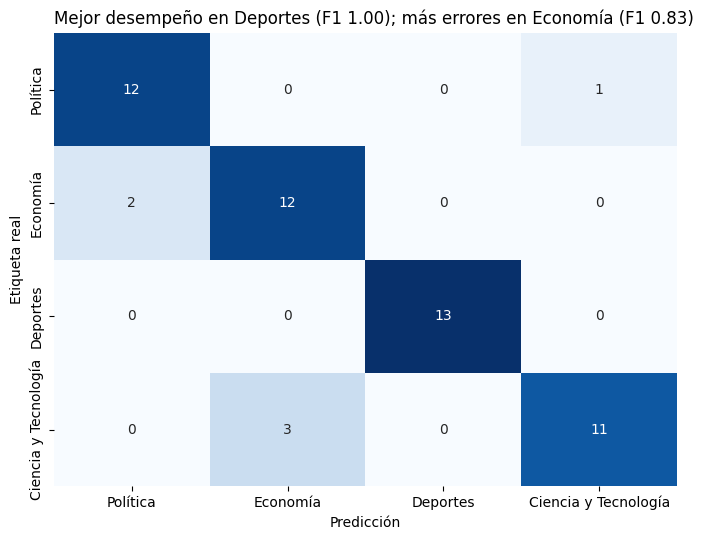

In [10]:
f1_por_categoria = pd.Series(
    f1_score(test["etiqueta"], test["prediccion_ft"], labels=CATEGORIAS, average=None), index=CATEGORIAS
)
mejor, peor = f1_por_categoria.idxmax(), f1_por_categoria.idxmin()

matriz = confusion_matrix(test["etiqueta"], test["prediccion_ft"], labels=CATEGORIAS)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=NOMBRES.values(), yticklabels=NOMBRES.values())
ax.set(xlabel="Predicción", ylabel="Etiqueta real")
ax.set_title(f"Mejor desempeño en {NOMBRES[mejor]} (F1 {f1_por_categoria[mejor]:.2f}); "
             f"más errores en {NOMBRES[peor]} (F1 {f1_por_categoria[peor]:.2f})", loc="left")
plt.tight_layout()
plt.show()

In [11]:
# Errores del modelo en test, para la reflexión por categoría
errores = test.query("etiqueta != prediccion_ft")[["titular", "etiqueta", "prediccion_ft", "etiqueta_llm"]]
with pd.option_context("display.max_colwidth", None):
    display(errores)

,titular,etiqueta,prediccion_ft,etiqueta_llm
28,El Niño en Perú: no está operativo ninguno de los 18 sistemas de alertas tempranas previstos desde 2017,ciencia_tecnologia,economia,ciencia_tecnologia
32,Daniel Barragán sobre Jorge Gavidia: “Las puertas de Obras siempre están abiertas”,politica,ciencia_tecnologia,politica
33,"Qué pasó con el experimento de Bukele de convertir a El Salvador en el ""país del bitcoin""",ciencia_tecnologia,economia,economia
36,Trump insta a los centros de datos a pagar un “dividendo” a las comunidades locales,ciencia_tecnologia,economia,economia
37,Ministro Guillermo Shinno Huamaní inaugura Central Solar Expansión Intipampa en Moquegua,economia,politica,economia
41,Cámara de Comercio de Lima: Renzo León-Velarde fue designado como nuevo gerente general,economia,politica,economia


### Reflexión por categoría

F1 del modelo fine-tuned en test: **Deportes 1.00**, Política 0.89, Ciencia y Tecnología 0.85, **Economía 0.83**.

- **Mejor: Deportes (13/13 correctos).** Tiene un vocabulario propio que no comparte con las otras categorías:
  nombres de clubes (Alianza, Cristal), jugadores, torneos (Clausura, Balón de Oro) y verbos como *golear* o *clasificar*.
  Además, el LLM tampoco se equivocó nunca con Deportes, así que el modelo aprendió con etiquetas limpias.
- **Peor: Economía.** Comparte actores y vocabulario con Política: cuando el titular nombra a un ministro o a
  una institución, el modelo lo lleva a Política aunque el hecho sea económico
  (*"Ministro Guillermo Shinno Huamaní inaugura Central Solar..."*, *"Cámara de Comercio de Lima: ... nuevo gerente general"*).
- **Ciencia y Tecnología: errores heredados del LLM.** Su sección mezcla temas que también son económicos o políticos:
  empresas tecnológicas, criptomonedas, minería ilegal, El Niño. En 2 de sus 3 errores
  (*"...el país del bitcoin"*, *"Trump insta a los centros de datos..."*) el LLM ya había etiquetado Economía, y el
  modelo aprendió esa etiqueta. Es el costo de la supervisión débil: el modelo reproduce los sesgos de quien lo etiqueta.
- **Política:** un solo error, en un titular de cita textual sin contexto temático
  (*"Las puertas de Obras siempre están abiertas"*).

En resumen, las fronteras difíciles son **Economía ↔ Política** (mismos actores) y **Ciencia y Tecnología ↔ Economía**
(noticias sobre empresas tecnológicas). Con solo el titular, muchas veces falta contexto: la bajada ayudaría a desambiguar.

## 6. Comparativa y decisión

Cada modelo se evalúa contra la etiqueta de referencia. El zero-shot usa sus 40 titulares (paso 1); el LLM y el
modelo fine-tuned se comparan sobre el mismo conjunto de test. La latencia es el tiempo de respuesta promedio por
titular medido en este equipo (CPU de 2 núcleos).

In [12]:
latencia_llm = json.loads(ruta_latencia.read_text())["seg_por_titular"] if ruta_latencia.exists() else None
resultados["LLM débil"] = {
    "modelo": etiquetas_llm["modelo_llm"].iloc[0], "evaluado_en": "Test", "n": len(test),
    **evaluar(test["etiqueta"], test["etiqueta_llm"]),
    "seg_por_titular": latencia_llm,
}
costos = {
    "Zero-shot": "Gratis; local en CPU, modelo de ~2 GB sin entrenamiento",
    "LLM débil": "API externa: gratis con límites de uso, de pago a escala; requiere internet",
    "Fine-tuned": "Gratis; local en CPU, ~500 MB; requiere entrenar (minutos)",
}
comparativa = (
    pd.DataFrame(resultados).T.loc[["Zero-shot", "LLM débil", "Fine-tuned"]]
    .assign(costo=pd.Series(costos))
    .astype({"accuracy": float, "f1_macro": float, "seg_por_titular": float})
    .round({"accuracy": 3, "f1_macro": 3, "seg_por_titular": 3})
)
comparativa.to_csv(MODELO / "comparativa.csv")
comparativa

,modelo,evaluado_en,n,accuracy,f1_macro,seg_por_titular,costo
Zero-shot,joeddav/xlm-roberta-large-xnli,40 titulares (10 por categoría),40,0.750,0.749,1.439,"Gratis; local en CPU, modelo de ~2 GB sin entr..."
LLM débil,gemini-3.5-flash-lite,Test,54,0.963,0.964,0.140,"API externa: gratis con límites de uso, de pag..."
Fine-tuned,distilbert-base-multilingual-cased,Test,54,0.889,0.891,0.031,"Gratis; local en CPU, ~500 MB; requiere entren..."


### Decisión

| | Zero-shot | LLM débil | Fine-tuned |
|---|---|---|---|
| F1 macro | 0.75 | **0.96** | 0.89 |
| Latencia por titular | 1.44 s | 0.14 s | **0.03 s** |
| Dónde corre | Local (CPU) | API externa | Local (CPU) |
| Costo por uso | Gratis | Gratis con límites; de pago a escala | Gratis |

Los dos modelos superan el piso del zero-shot (0.75). El zero-shot queda descartado: es el menos preciso y el
más lento, porque evalúa cada titular contra las 4 categorías con un modelo grande.

**Elección para un entorno real: el modelo fine-tuned (DistilBERT), con el LLM como apoyo.**

- **Costo y operación:** corre en una laptop sin GPU, sin internet y sin pagar por petición. El LLM depende de
  un servicio externo con límites de uso, costo por volumen y modelos que pueden dejar de estar disponibles
  (en este trabajo `gemini-2.5-flash` ya no estaba disponible para cuentas nuevas).
- **Latencia:** es unas 5 veces más rápido que el LLM y unas 46 veces más rápido que el zero-shot, lo que
  permite clasificar en tiempo real todo lo que publica un diario.
- **Precisión:** el LLM es más preciso (0.96 vs. 0.89). Sobre 54 titulares de test, la diferencia es de 4 errores.
  Para cerrarla sin perder las ventajas anteriores, el LLM puede usarse solo para **etiquetar más datos y reentrenar**
  periódicamente, o para revisar los titulares en los que el modelo tenga baja confianza.

Si el volumen fuera pequeño y la precisión fuera lo único importante, el LLM sería la mejor opción.

## Conclusiones

1. **Línea base:** el zero-shot multilingüe (`xlm-roberta-large-xnli`) logra F1 macro 0.75 sin entrenamiento; es el piso a superar.
2. **Supervisión débil:** Gemini (`gemini-3.5-flash-lite`) etiquetó los 360 titulares en unos segundos, con 93.6 % de acuerdo
   con la etiqueta de la sección. Sus desacuerdos se concentran en noticias que mezclan temas (El Niño, empresas
   tecnológicas, columnas de opinión) y en ellos su confianza promedio baja (0.83 frente a 0.96 en los aciertos).
   En la **auditoría humana** de 20 predicciones al azar, el acuerdo fue de **20/20 = 100 %**. En 2 de esos 20 casos
   el LLM no coincide con la sección del diario (noticias de El Niño y de minería ilegal publicadas en Ciencia y
   Tecnología que el LLM etiquetó como Economía), pero se consideraron correctas porque el titular trata el impacto
   económico. Esto muestra que la etiqueta de la sección no siempre es la única respuesta válida.
3. **Fine-tuning:** DistilBERT entrenado solo con las etiquetas del LLM alcanzó F1 macro **0.89** en test, superando
   ampliamente al zero-shot. El mejor resultado en validación se obtuvo en la época 2.
4. **Límite:** el modelo fine-tuned no supera al LLM que lo etiquetó, porque aprende también sus errores.
5. **Decisión:** para producción se elige el modelo fine-tuned por costo y latencia, apoyado en el LLM para ampliar el
   etiquetado y revisar casos dudosos.
6. **Advertencia:** el test tiene 54 titulares, por lo que cada error mueve la accuracy casi 2 puntos. Las diferencias
   entre modelos deben leerse con esa cautela.